# Import Thư viên

In [248]:
import pandas as pd, numpy as np, matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, accuracy_score

In [249]:
df = pd.read_csv("customer_segmentation.csv")
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [250]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1',
       'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response'],
      dtype='object')

In [251]:
df.shape

(2240, 29)

In [252]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [253]:
df.isna().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

In [254]:
df.dropna()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [255]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


# Feature engineering

In [256]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")

In [257]:
df["Tenure_days"] = (df["Dt_Customer"].max() - df["Dt_Customer"]).dt.days
df["Tenure_days"]

0       663
1       113
2       312
3       139
4       161
       ... 
2235    381
2236     19
2237    155
2238    156
2239    622
Name: Tenure_days, Length: 2240, dtype: int64

In [258]:
df["Age"] = 2014 - df["Year_Birth"]

In [259]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Tenure_days,Age
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,0,0,0,0,0,3,11,1,663,57
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,0,0,0,0,0,3,11,0,113,60
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,0,0,0,0,0,3,11,0,312,49
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,0,0,0,0,3,11,0,139,30
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,0,0,0,0,0,3,11,0,161,33


In [260]:
df.describe()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Tenure_days,Age
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,2013-07-10 10:01:42.857142784,49.109375,303.935714,26.302232,166.950000,...,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107,353.582143,45.194196
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,2012-07-30 00:00:00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,0.000000,18.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,2013-01-16 00:00:00,24.000000,23.750000,1.000000,16.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,180.750000,37.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,2013-07-08 12:00:00,49.000000,173.500000,8.000000,67.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,355.500000,44.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,2013-12-30 06:00:00,74.000000,504.250000,33.000000,232.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000,529.000000,55.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,2014-06-29 00:00:00,99.000000,1493.000000,199.000000,1725.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000,699.000000,121.000000
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,NaN,28.962453,336.597393,39.773434,225.715373,...,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274,202.122512,11.984069


In [261]:
df["Total_children"] = df["Kidhome"] + df["Teenhome"]
df["Total_children"]

0       0
1       2
2       0
3       1
4       1
       ..
2235    1
2236    3
2237    0
2238    1
2239    2
Name: Total_children, Length: 2240, dtype: int64

In [262]:
df["Total_Spending"] = df[["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]].sum(axis=1)
df["Total_Spending"]

0       1617
1         27
2        776
3         53
4        422
        ... 
2235    1341
2236     444
2237    1241
2238     843
2239     172
Name: Total_Spending, Length: 2240, dtype: int64

In [263]:
df["Total_Purchases"] = df[["NumWebPurchases","NumCatalogPurchases","NumStorePurchases"]].sum(axis=1)
df["Total_Purchases"]

0       22
1        4
2       20
3        6
4       14
        ..
2235    16
2236    15
2237    18
2238    21
2239     8
Name: Total_Purchases, Length: 2240, dtype: int64

In [264]:
df["Total_Cmp"] = df[["AcceptedCmp1","AcceptedCmp2","AcceptedCmp3","AcceptedCmp4","AcceptedCmp5"]].sum(axis=1)
df["Total_Cmp"]

0       0
1       0
2       0
3       0
4       0
       ..
2235    0
2236    1
2237    1
2238    0
2239    0
Name: Total_Cmp, Length: 2240, dtype: int64

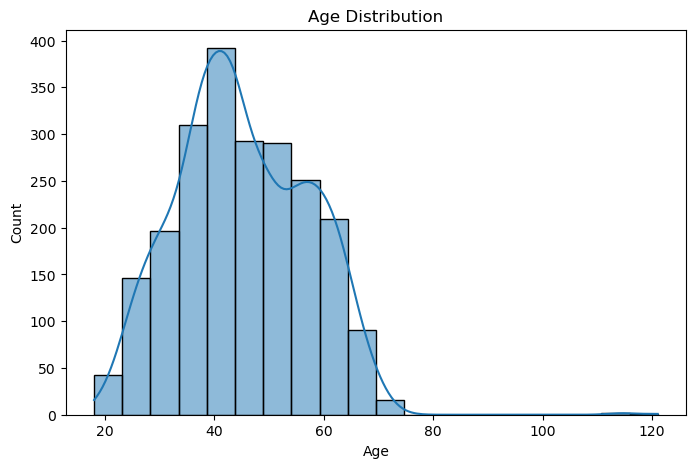

In [265]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=20, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.show()

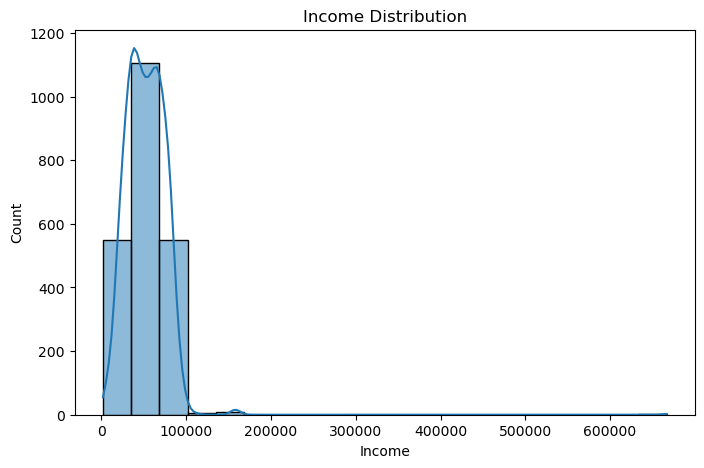

In [266]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Income"], bins=20, kde=True)
plt.title("Income Distribution")
plt.show()

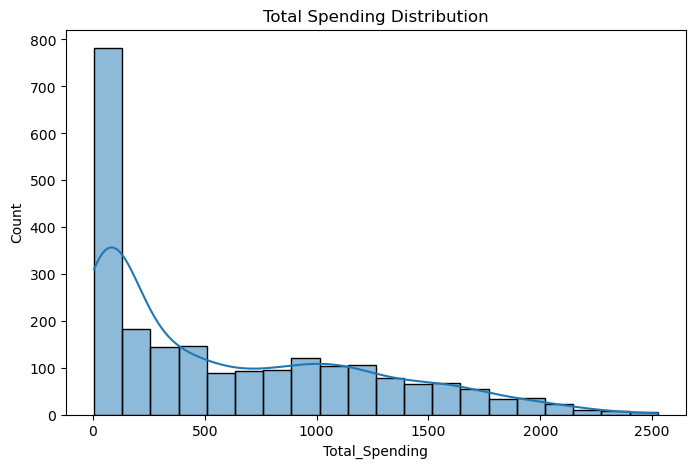

In [267]:
plt.figure(figsize =(8,5))
sns.histplot(df["Total_Spending"], bins = 20, kde = True)
plt.title("Total Spending Distribution")
plt.show()

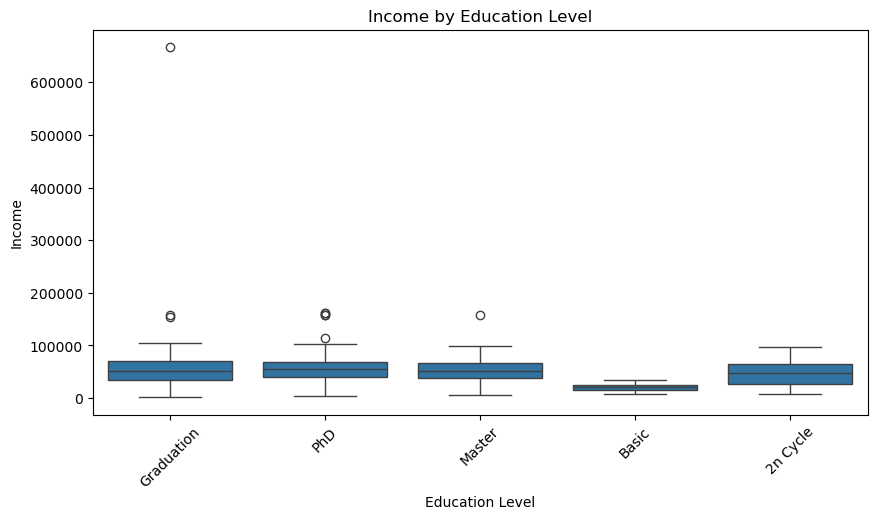

In [268]:
plt.figure(figsize=(10, 5))
sns.boxplot(x="Education", y="Income", data=df)
plt.xticks(rotation=45)
plt.title("Income by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Income")
plt.show()

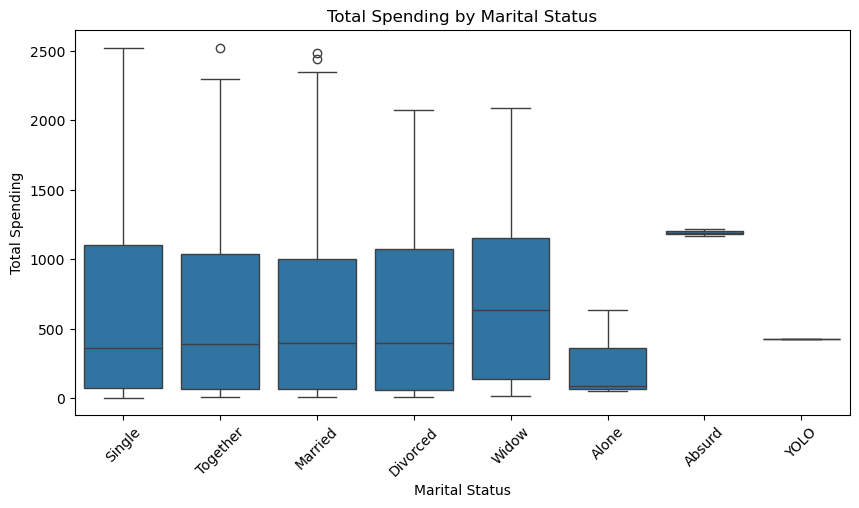

In [269]:
plt.figure(figsize=(10, 5))

sns.boxplot(x="Marital_Status", y="Total_Spending", data=df)

plt.xticks(rotation=45)
plt.title("Total Spending by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Total Spending")

plt.show()

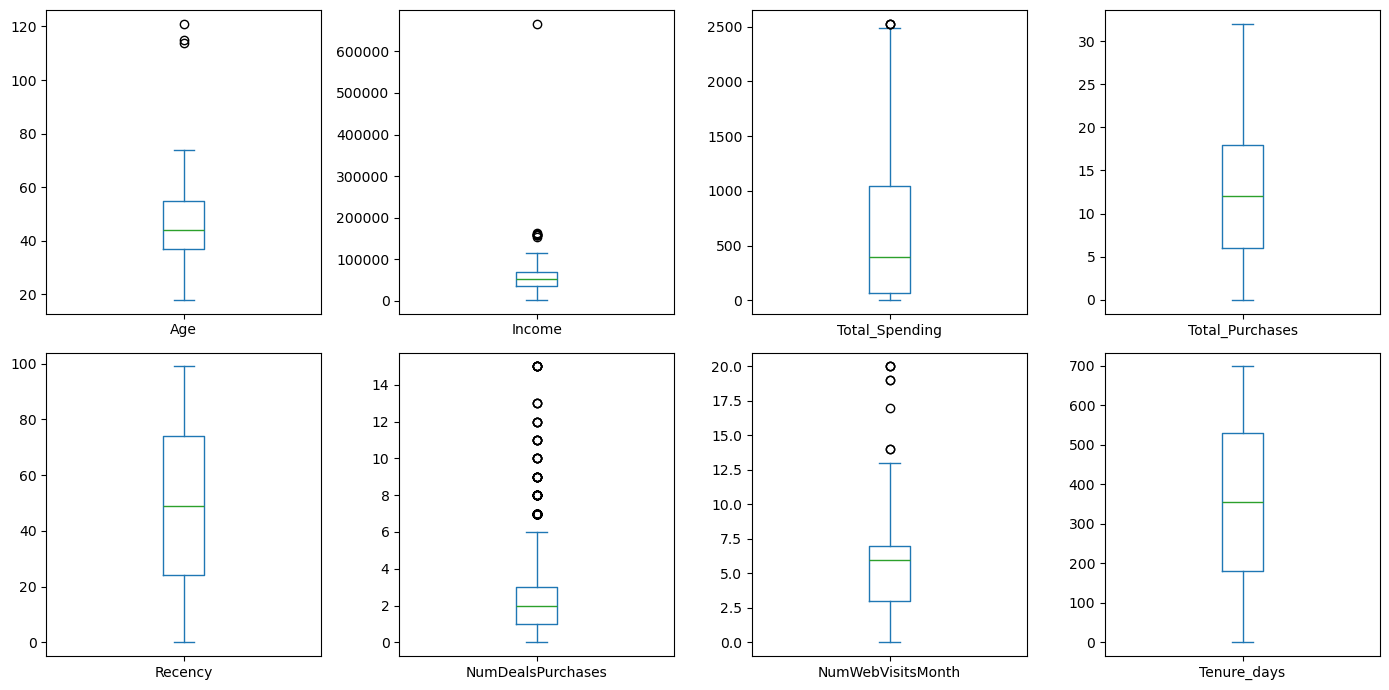

Age: 3 outlier
Income: 8 outlier
Total_Spending: 3 outlier
Total_Purchases: 0 outlier
Recency: 0 outlier
NumDealsPurchases: 86 outlier
NumWebVisitsMonth: 8 outlier
Tenure_days: 0 outlier


In [270]:
num_cols = ["Age","Income","Total_Spending","Total_Purchases","Recency",
            "NumDealsPurchases","NumWebVisitsMonth","Tenure_days"]

# 1. Vẽ boxplot
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
df[num_cols].plot(kind="box", subplots=True, layout=(2,4), figsize=(14,7))
plt.tight_layout()
plt.show()

# 2. Đếm outlier theo quy tắc IQR
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(f"{c}: {n} outlier")

In [271]:
cols = ["Age", "Income", "Total_Spending", "NumDealsPurchases", "NumWebVisitsMonth"]

for c in cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df[c] = df[c].clip(lower, upper)

# Xử lý outlier

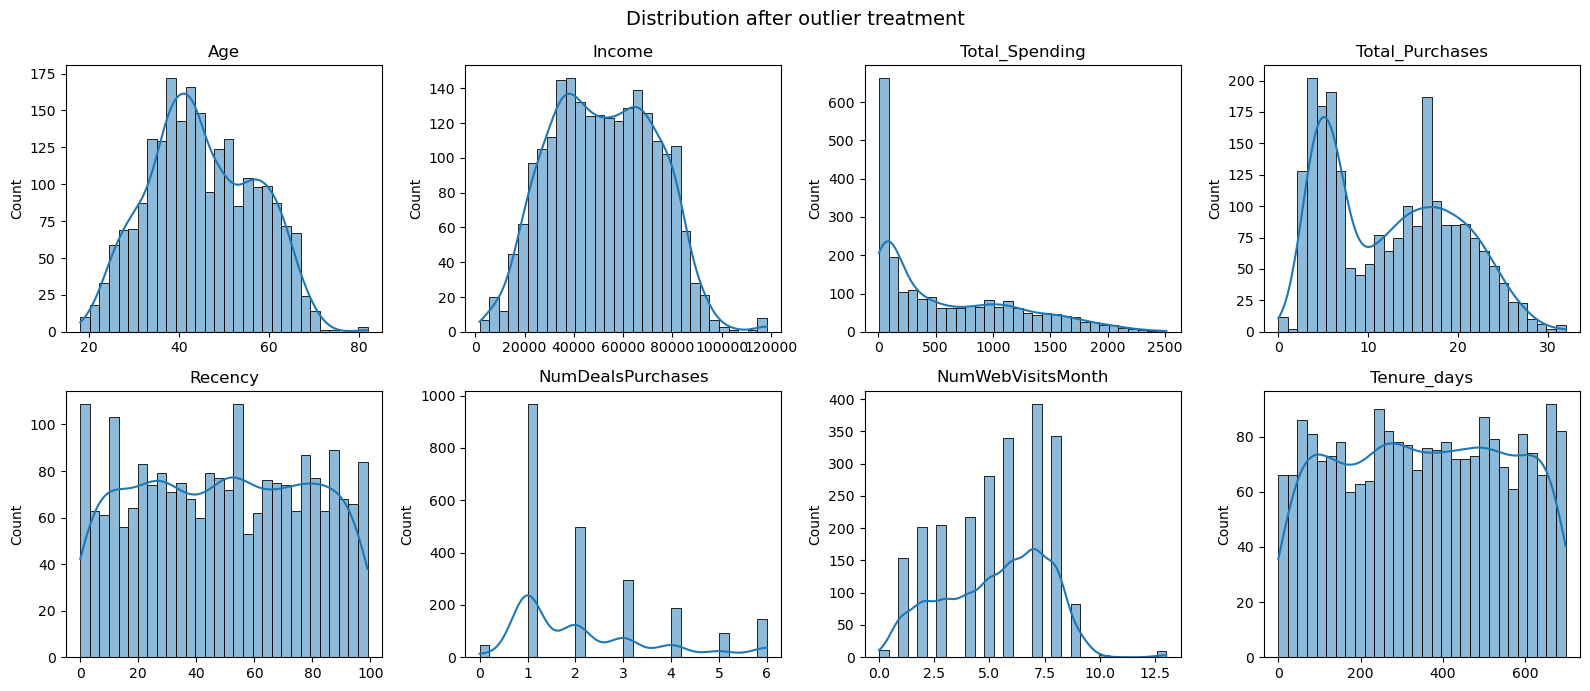

In [272]:
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

num_cols = ["Age", "Income", "Total_Spending", "Total_Purchases", "Recency",
            "NumDealsPurchases", "NumWebVisitsMonth", "Tenure_days"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], bins=30, kde=True, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")

plt.suptitle("Distribution after outlier treatment", fontsize=14)
plt.tight_layout()
plt.show()

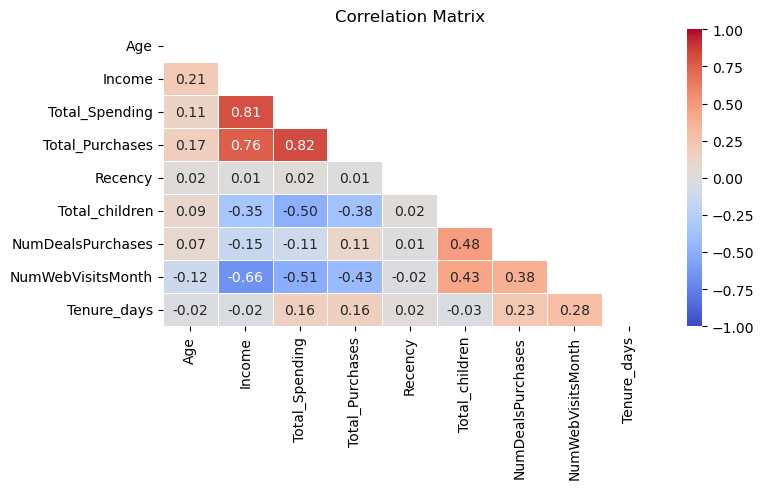

In [273]:
# Biểu đồ heatmap
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

num_cols = ["Age", "Income", "Total_Spending", "Total_Purchases", "Recency",
            "Total_children", "NumDealsPurchases", "NumWebVisitsMonth", "Tenure_days"]

corr = df[num_cols].corr()

# Chỉ hiện nửa tam giác dưới cho gọn
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# Scaling

In [274]:
# Bỏ dòng thiếu dữ liệu
df = df.dropna(subset=feats).copy()

In [275]:
feats = ["Age", "Income", "Total_Spending", "Total_children",
         "NumDealsPurchases", "NumWebVisitsMonth", "Tenure_days"]

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()


In [276]:
X_scaler = scaler.fit_transform(X)
X_scaler

array([[ 1.00842346,  0.29748327,  1.67568718, ...,  0.51035164,
         0.72412901,  1.52912861],
       [ 1.26334776, -0.26266902, -0.96242299, ..., -0.140736  ,
        -0.12851174, -1.18841056],
       [ 0.32862533,  0.93747411,  0.28030941, ..., -0.79182364,
        -0.55483211, -0.20515548],
       ...,
       [-1.03097092,  0.24253192,  1.05183219, ..., -0.79182364,
         0.29780863, -0.98088939],
       [ 1.09339823,  0.8250067 ,  0.39147506, ..., -0.140736  ,
        -0.98115248, -0.97594841],
       [ 1.26334776,  0.04723378, -0.72184062, ...,  0.51035164,
         0.72412901,  1.32654842]])

# Chọn K

c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

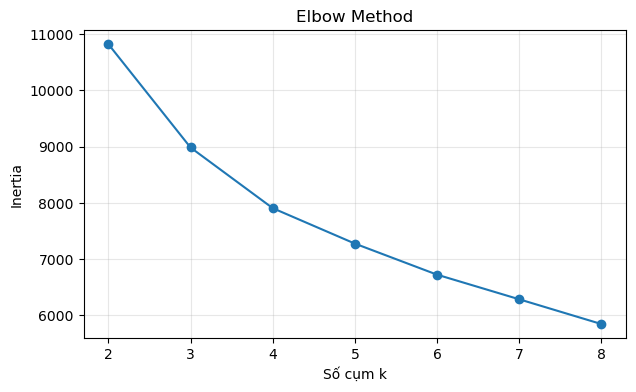

In [277]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

ks = range(2, 9)
inertia = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X)
    inertia.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(ks, inertia, "o-")
plt.title("Elbow Method")
plt.xlabel("Số cụm k")
plt.ylabel("Inertia")
plt.xticks(list(ks))
plt.grid(alpha=0.3)
plt.show()

# Chọn k = 6

In [278]:
from sklearn.cluster import KMeans

K = 6
km = KMeans(K, n_init=20, random_state=42).fit(X)
df["Segment"] = km.labels_


c:\Users\ADMIN\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


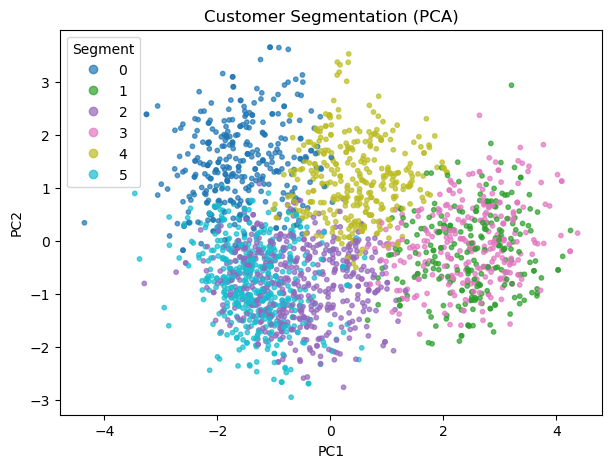

In [279]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
%matplotlib inline

plt.close("all")   # đóng các figure cũ, tránh hiện 2 hình

pca = PCA(2, random_state=42)
P = pca.fit_transform(X)

plt.figure(figsize=(7, 5))
sc = plt.scatter(P[:, 0], P[:, 1], c=df["Segment"], cmap="tab10", s=10, alpha=0.7)
plt.legend(*sc.legend_elements(), title="Segment")
plt.title("Customer Segmentation (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

In [280]:
cluster_summary = df.groupby("Segment")[
    ["Age", "Income", "Total_Spending", "Total_children",
     "NumDealsPurchases", "NumWebVisitsMonth", "Tenure_days"]
].mean().round(2)

cluster_summary["Size"] = df["Segment"].value_counts().sort_index()
cluster_summary

,Age,Income,Total_Spending,Total_children,NumDealsPurchases,NumWebVisitsMonth,Tenure_days,Size
Segment,,,,,,,,
0,47.21,46114.77,438.83,1.72,4.91,7.02,465.55,323
1,33.57,78261.06,1477.06,0.12,1.04,2.62,374.67,251
2,47.33,44564.98,181.63,1.42,1.86,5.19,163.79,509
3,56.83,75383.05,1174.88,0.17,1.06,2.23,260.89,289
4,51.20,62756.22,999.87,0.92,2.75,5.65,494.58,348
5,36.30,28441.21,106.46,0.84,1.73,7.20,419.57,496


In [281]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Z_CostContact,Z_Revenue,Response,Tenure_days,Age,Total_children,Total_Spending,Total_Purchases,Total_Cmp,Segment
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,3,11,1,663,57,0,1617.0,22,0,4
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,3,11,0,113,60,2,27.0,4,0,2
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,3,11,0,312,49,0,776.0,20,0,3
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,3,11,0,139,30,1,53.0,6,0,5
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,3,11,0,161,33,1,422.0,14,0,0


In [282]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

y = df["Segment"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

best = None
for n in range(1, 31, 2):
    s = cross_val_score(KNeighborsClassifier(n), Xtr, ytr, cv=5).mean()
    if best is None or s > best[1]:
        best = (n, s)
print("best knn", best)

knn = KNeighborsClassifier(best[0]).fit(Xtr, ytr)
print(accuracy_score(yte, knn.predict(Xte)))
print(classification_report(yte, knn.predict(Xte)))



best knn (19, np.float64(0.929453330150394))
0.9436936936936937
              precision    recall  f1-score   support

           0       1.00      0.92      0.96        65
           1       0.96      0.94      0.95        50
           2       0.91      0.98      0.94       102
           3       0.95      0.91      0.93        58
           4       0.95      0.90      0.93        70
           5       0.93      0.97      0.95        99

    accuracy                           0.94       444
   macro avg       0.95      0.94      0.94       444
weighted avg       0.95      0.94      0.94       444

